# Environment Setup

In [ ]:
import os
os.environ["TMPDIR"] = "/data/khawlachrifialaoui/tmp"
os.makedirs(os.environ["TMPDIR"], exist_ok=True)


# Libraries and GPU Setup

In [ ]:
import os
import glob
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

import kagglehub
from torchvision import transforms, utils
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt

from torchvision.models import inception_v3, Inception_V3_Weights
from torchvision.models.inception import InceptionOutputs
from torchvision.transforms import Resize
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)
print("GPUs:", torch.cuda.device_count())


/home/khawlachrifialaoui/miniconda3/envs/py311/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cuda
GPUs: 1


# CelebA Dataset Download

In [ ]:
celeba_path = kagglehub.dataset_download("jessicali9530/celeba-dataset")
print("CelebA downloaded at:", celeba_path)

image_paths = glob.glob(celeba_path + "/**/*.jpg", recursive=True)
print("Found", len(image_paths), "images")

CelebA downloaded at: /home/khawlachrifialaoui/.cache/kagglehub/datasets/jessicali9530/celeba-dataset/versions/2
Found 202599 images


# Data Preprocessing and DataLoader

In [ ]:
IMG_SIZE = 64
BATCH_SIZE = 128

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),   # [-1,1]
])

class CelebADataset(Dataset):
    def __init__(self, paths, transform=None):
        self.paths = paths
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img

dataset = CelebADataset(image_paths, transform)
loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

# DCGAN Generator Architecture

In [ ]:
LATENT_DIM = 100

class Generator(nn.Module):
    def __init__(self, latent_dim=100):
        super().__init__()
        self.model = nn.Sequential(
            # input Z → 4×4×512
            nn.Linear(latent_dim, 4*4*512, bias=False),
            nn.BatchNorm1d(4*4*512),
            nn.ReLU(True),

            nn.Unflatten(1, (512, 4, 4)),  # reshape

            # 8×8×256
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            # 16×16×128
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            # 32×32×64
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            # 64×64×3
            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, z):
        return self.model(z)


# DCGAN Discriminator Architecture

In [ ]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            # 32×32×64
            nn.Conv2d(3, 64, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),

            # 16×16×128
            nn.Conv2d(64, 128, 4, 2, 1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            # 8×8×256
            nn.Conv2d(128, 256, 4, 2, 1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            # 4×4×512
            nn.Conv2d(256, 512, 4, 2, 1),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Flatten(),
            nn.Linear(4*4*512, 1)
        )

    def forward(self, img):
        return self.model(img)


# DCGAN Model Initialization and Optimizers

In [ ]:
device = "cuda"
generator = Generator(LATENT_DIM).to(device)
discriminator = Discriminator().to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer_g = optim.Adam(generator.parameters(), lr=2e-4, betas=(0.5, 0.5))
optimizer_d = optim.Adam(discriminator.parameters(), lr=2e-4, betas=(0.5, 0.5))


# DCGAN Checkpoint Saving and Loading

In [ ]:
import os
checkpoint_dir = "./checkpoints_dcgan"
os.makedirs(checkpoint_dir, exist_ok=True)
checkpoint_path = os.path.join(checkpoint_dir, "dcgan_celeba.pth")

def save_checkpoint(epoch):
    torch.save({
        "epoch": epoch,
        "generator_state_dict": generator.state_dict(),
        "discriminator_state_dict": discriminator.state_dict(),
        "optimizer_g_state_dict": optimizer_g.state_dict(),
        "optimizer_d_state_dict": optimizer_d.state_dict(),
    }, checkpoint_path)
    print(f"[Checkpoint] Saved at epoch {epoch} → {checkpoint_path}")

def load_checkpoint():
    if os.path.isfile(checkpoint_path):
        ckpt = torch.load(checkpoint_path, map_location=device)
        generator.load_state_dict(ckpt["generator_state_dict"])
        discriminator.load_state_dict(ckpt["discriminator_state_dict"])
        optimizer_g.load_state_dict(ckpt["optimizer_g_state_dict"])
        optimizer_d.load_state_dict(ckpt["optimizer_d_state_dict"])
        start_epoch = ckpt["epoch"] + 1
        print(f"[Checkpoint] Loaded from {checkpoint_path}, resuming at epoch {start_epoch}")
        return start_epoch
    else:
        print("[Checkpoint] No checkpoint found, starting from scratch.")
        return 1

start_epoch = load_checkpoint()

[Checkpoint] Loaded from ./checkpoints_dcgan/dcgan_celeba.pth, resuming at epoch 91


# Fixed Noise for Image Sampling

In [ ]:
fixed_noise = torch.randn(16, LATENT_DIM, device=device)


# Generate and Visualize Samples

In [ ]:
def show_generated(epoch):
    generator.eval()
    with torch.no_grad():
        fake = generator(fixed_noise).detach().cpu()
        fake = (fake + 1) / 2  # [-1,1] → [0,1]

    grid = utils.make_grid(fake, nrow=4)
    plt.figure(figsize=(4,4))
    plt.imshow(grid.permute(1,2,0))
    plt.title(f"Epoch {epoch}")
    plt.axis("off")
    plt.show()
    generator.train()


# DCGAN Training Loop

Epoch 91/100 - G: 20119.4218 - D: 72.1907
Epoch 92/100 - G: 20537.2038 - D: 64.2747
Epoch 93/100 - G: 20873.8600 - D: 67.5484
Epoch 94/100 - G: 21107.1737 - D: 57.9489
Epoch 95/100 - G: 21137.8266 - D: 63.0287


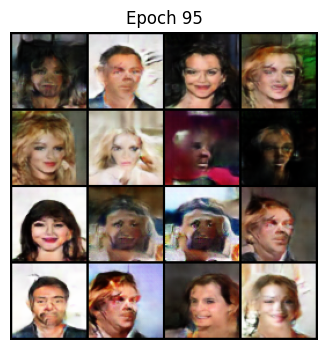

[Checkpoint] Saved at epoch 95 → ./checkpoints_dcgan/dcgan_celeba.pth
Epoch 96/100 - G: 21094.0546 - D: 58.6138
Epoch 97/100 - G: 20829.8126 - D: 63.0797
Epoch 98/100 - G: 21328.3257 - D: 53.4758
Epoch 99/100 - G: 21861.9975 - D: 51.0510
Epoch 100/100 - G: 22011.6919 - D: 52.6236


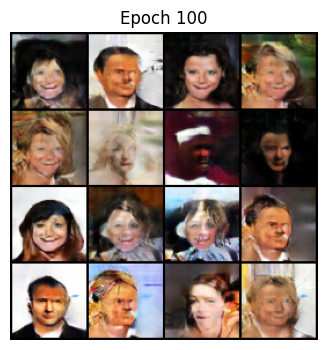

[Checkpoint] Saved at epoch 100 → ./checkpoints_dcgan/dcgan_celeba.pth
[Final] Saved trained generator weights to ./checkpoints_dcgan/dcgan_generator_final.pth


In [ ]:
EPOCHS = 100

for epoch in range(start_epoch, EPOCHS+1):
    gen_loss_total = 0.0
    disc_loss_total = 0.0

    for real in loader:
        real = real.to(device)
        batch_size = real.size(0)

        #Discriminator
        noise = torch.randn(batch_size, LATENT_DIM, device=device)
        fake = generator(noise)

        real_logits = discriminator(real)
        fake_logits = discriminator(fake.detach())

        real_labels = torch.ones_like(real_logits)
        fake_labels = torch.zeros_like(fake_logits)

        d_loss_real = criterion(real_logits, real_labels)
        d_loss_fake = criterion(fake_logits, fake_labels)
        d_loss = d_loss_real + d_loss_fake

        optimizer_d.zero_grad()
        d_loss.backward()
        optimizer_d.step()

        # Generator
        fake_logits2 = discriminator(fake)
        g_loss = criterion(fake_logits2, real_labels)

        optimizer_g.zero_grad()
        g_loss.backward()
        optimizer_g.step()

        gen_loss_total += g_loss.item()
        disc_loss_total += d_loss.item()

    print(f"Epoch {epoch}/{EPOCHS} - G: {gen_loss_total:.4f} - D: {disc_loss_total:.4f}")

    if epoch % 5 == 0 or epoch == 1:
        show_generated(epoch)
        save_checkpoint(epoch)

final_gen_path = os.path.join(checkpoint_dir, "dcgan_generator_final.pth")
torch.save(generator.state_dict(), final_gen_path)
print(f"[Final] Saved trained generator weights to {final_gen_path}")




# FID and Inception Score Utilities

In [ ]:
inception_device = torch.device("cpu")
print("Inception device:", inception_device)

def denorm_01(x):
    return (x + 1) / 2  # [-1,1] -> [0,1]

def compute_mu_sigma(feats: torch.Tensor):
    mu = feats.mean(dim=0)
    xm = feats - mu
    sigma = xm.T @ xm / (feats.size(0) - 1)
    return mu, sigma

def matrix_sqrt(m: torch.Tensor):
    m = (m + m.T) / 2
    eigvals, eigvecs = torch.linalg.eigh(m)
    eigvals = torch.clamp(eigvals, min=0)
    sqrt_eigvals = torch.sqrt(eigvals)
    return eigvecs @ torch.diag(sqrt_eigvals) @ eigvecs.T

def fid_from_mus_sigmas(mu1, sigma1, mu2, sigma2):
    diff = mu1 - mu2
    covmean = matrix_sqrt(sigma1 @ sigma2)
    fid = diff @ diff + torch.trace(sigma1 + sigma2 - 2 * covmean)
    return fid.item()

def inception_score_from_probs(probs: torch.Tensor, splits: int = 4):
    N = probs.size(0)
    split_size = N // splits
    scores = []
    for i in range(splits):
        part = probs[i * split_size : (i + 1) * split_size]
        py = part.mean(dim=0)
        kl = part * (torch.log(part + 1e-8) - torch.log(py[None, :] + 1e-8))
        kl = kl.sum(dim=1).mean()
        scores.append(torch.exp(kl))
    scores = torch.stack(scores)
    return scores.mean().item(), scores.std().item()



Inception device: cpu


# Inception Model Setup for Evaluation

In [ ]:
os.environ["TORCH_HOME"] = "/data/khawlachrifialaoui/torch_cache"
os.makedirs(os.environ["TORCH_HOME"], exist_ok=True)

weights = Inception_V3_Weights.IMAGENET1K_V1

inception_logits = inception_v3(weights=weights).to(inception_device)
inception_logits.eval()

inception_features = inception_v3(weights=weights).to(inception_device)
inception_features.fc = nn.Identity()
inception_features.eval()

resize_299 = Resize((299, 299))


# Feature Extraction for FID and IS

In [ ]:
@torch.no_grad()
def get_features(dataloader_or_tensor, model, max_images=200, is_tensor=False):
    feats = []
    if is_tensor:
        x = dataloader_or_tensor
        x = denorm_01(x).clamp(0, 1)
        x = resize_299(x)
        x = x.to(inception_device)
        out = model(x)
        if isinstance(out, InceptionOutputs) or isinstance(out, tuple):
            out = out.logits if hasattr(out, "logits") else out[0]
        feats.append(out.cpu())
    else:
        seen = 0
        for x in dataloader_or_tensor:
            x = x.to(inception_device)
            x = denorm_01(x).clamp(0, 1)
            x = resize_299(x)
            out = model(x)
            if isinstance(out, InceptionOutputs) or isinstance(out, tuple):
                out = out.logits if hasattr(out, "logits") else out[0]
            feats.append(out.cpu())
            seen += x.size(0)
            if seen >= max_images:
                break
    feats = torch.cat(feats, dim=0)
    if feats.size(0) > max_images:
        feats = feats[:max_images]
    return feats

# DCGAN Evaluation (FID & Inception Score)

In [ ]:
NUM_SAMPLES = 128
BATCH_FAKE  = 16

print("Collecting real features for FID (DCGAN)...")
real_feats = get_features(loader, inception_features, max_images=NUM_SAMPLES, is_tensor=False)
mu_real, sigma_real = compute_mu_sigma(real_feats)
print(f"Collected {real_feats.size(0)} real features.")

print("Sampling DCGAN images and collecting features/probs...")
generator.eval()
fake_feats_list = []
probs_list      = []
fake_seen       = 0

while fake_seen < NUM_SAMPLES:
    bs = min(BATCH_FAKE, NUM_SAMPLES - fake_seen)
    z = torch.randn(bs, LATENT_DIM, device=device)
    fake_batch = generator(z)                    # [-1,1]
    fake_batch = denorm_01(fake_batch).clamp(0, 1)

    x_in = resize_299(fake_batch).to(inception_device)

    out_f = inception_features(x_in)
    if isinstance(out_f, InceptionOutputs) or isinstance(out_f, tuple):
        out_f = out_f.logits if hasattr(out_f, "logits") else out_f[0]
    fake_feats_list.append(out_f.cpu())

    out_l = inception_logits(x_in)
    if isinstance(out_l, InceptionOutputs) or isinstance(out_l, tuple):
        out_l = out_l.logits if hasattr(out_l, "logits") else out_l[0]
    p_yx = F.softmax(out_l, dim=1)
    probs_list.append(p_yx.cpu())

    fake_seen += bs
    print(f"  Generated {fake_seen}/{NUM_SAMPLES} fake images...", end="\r")

    del z, fake_batch, x_in, out_f, out_l, p_yx
    torch.cuda.empty_cache()

fake_feats = torch.cat(fake_feats_list, dim=0)[:NUM_SAMPLES]
mu_fake, sigma_fake = compute_mu_sigma(fake_feats)

probs_fake = torch.cat(probs_list, dim=0)[:NUM_SAMPLES]

fid_value = fid_from_mus_sigmas(mu_real, sigma_real, mu_fake, sigma_fake)
is_mean, is_std = inception_score_from_probs(probs_fake, splits=4)


print(f"FID: {fid_value:.2f}")
print(f"Inception Score: {is_mean:.2f} ± {is_std:.2f}")


Collected 128 real features.
Sampling DCGAN images and collecting features/probs...
FID: 73.63d 128/128 fake images...
Inception Score: 1.85 ± 0.13
